# Rebellion Experiment

Use the BehaviorSpace results to compare activity, outbursts, and the relationship between jail policy and legitimacy. The sweep varies vision, police density, maximum jail term, and legitimacy feedback (λ). Each setting uses the same three seeds and runs for 180 ticks.

## Read the BehaviorSpace data

Each row is one observation from one run at one tick. First load the file, then give the columns shorter names and sort the observations within each run.

In [1]:
import pandas as pd

url = "https://github.com/DACSS-Complexity/s9_rebellion/raw/main/O_mexp.csv"
data = pd.read_csv(url, skiprows=6)

In [2]:
# Short names make the analysis easier to read.
data = data.rename(columns={
    '[run number]': 'run',
    'ticks': 'tick',
    'vision_in_patches': 'vision',
    'police-density': 'police_pct',
    'maximum-jail-term': 'max_jail',
    'legitimacy-feedback': 'feedback',
    'experiment-seed': 'seed',
    'effective-legitimacy': 'effective_legitimacy',
    'arrests-this-tick': 'arrests',
    'jailed-share': 'jailed_share',
    'count citizens with [active?]': 'active',
    'count citizens with [hidden?]': 'jailed',
})

# BehaviorSpace can interleave rows from different runs.
data = data.sort_values(['run', 'tick'])
print(f"{data['run'].nunique():,} runs, {len(data):,} tick records")

2,700 runs, 488,700 tick records


#### Table 1 · First five observations

**What it shows.** See what one row contains before grouping the data by run.

In [3]:
data[["run", "tick", "active", "jailed", "effective_legitimacy"]].head()

,run,tick,active,jailed,effective_legitimacy
7,1,0,0,0,0.82
12,1,1,491,10,0.82
21,1,2,479,20,0.82
31,1,3,471,27,0.82
39,1,4,464,36,0.82


**What we observe.** Tick 0 is the starting point, before anyone has taken a turn. By tick 1, 491 citizens are active and 10 are jailed. By tick 4, 36 are jailed. Legitimacy stays at 0.82 because this example uses λ = 0. Reading down a single run shows how the model can change from one tick to the next.

## Prepare one summary per run

An outburst starts when more than 50 citizens are active and ends when fewer than 50 are active. At exactly 50, an outburst neither starts nor ends. The peak is the largest number of active citizens during an outburst. The valley is the smallest number between two outbursts. If an outburst is still ongoing at tick 180, we can measure its peak and size so far. Its full duration is unknown.

Each run gets one label based on what happened by tick 180.

- **No outburst.** There were never more than 50 active citizens at once.
- **Single completed.** One outburst started and ended.
- **Sustained through the window.** One outburst started and had yet to end at tick 180.
- **Recurrent.** Two or more outbursts started. The last one may still be ongoing at tick 180.

[Epstein (2002), Model I](https://pdodds.w3.uvm.edu/files/papers/others/2002/epstein2002a.pdf#page=3)

### Pseudocode

1. Set the outburst cutoff to 50. Start an episode table and a run table.
2. Take one run at a time. Read its ticks in order.
3. At each tick:
   - If no outburst is underway and more than 50 citizens are active, start one. If a previous episode ended, record the waiting time and the lowest activity during the gap.
   - If an outburst is underway, end it when fewer than 50 citizens are active. Until then, update its peak and add the number of active citizens at that tick to its total.
   - While waiting for the next outburst, track the smallest number of active citizens. A count of exactly 50 leaves the episode status unchanged.
4. If an outburst has yet to end at the last tick, retain it and leave its final duration blank.
5. Classify the run and summarize its measurements from tick 1 onward.
6. Build the episode and run tables for the comparisons below.

The episode table has one row per outburst. The run table has one row per run, including runs with no outbursts.

In [4]:
# 1. Set the cutoff and create a table for episodes and a table for runs.
settings = ['vision', 'police_pct', 'max_jail', 'feedback']
keys = [*settings, 'seed']
cutoff = 50
episodes, runs = [], []
# 2. Read one run at a time, with its ticks already sorted.
for run_id, run in data.groupby('run', sort=False):
    identifiers = {'run': run_id, **run.iloc[0][keys].to_dict()}
    episode = None
    previous_end = None
    valley = None
    starts = 0
    # 3. Read the active count at each tick.
    for tick, active in run[['tick', 'active']].itertuples(index=False, name=None):
        # Start an outburst above 50. Record the wait and valley if there was a prior episode.
        if episode is None and active > cutoff:
            episode = {**identifiers, 'start_tick': tick, 'peak_active': active,
                       'active_person_ticks': active, 'valley_active': valley,
                       'waiting_ticks': None if previous_end is None else tick - previous_end}
            starts += 1
        elif episode is not None:
            # End the outburst below 50. This tick begins the next quiet interval.
            if active < cutoff:
                episodes.append({**episode, 'end_tick': tick,
                                 'duration_ticks': tick - episode['start_tick'], 'open_at_end': False})
                episode, previous_end, valley = None, tick, active
            else:
                # At 50 or above, keep the episode open and update its peak and cumulative activity.
                episode['peak_active'] = max(episode['peak_active'], active)
                episode['active_person_ticks'] += active
        # Between outbursts, keep the lowest active count seen so far.
        elif previous_end is not None:
            valley = min(valley, active)
    # 4. If the run ends during an outburst, save it as open with no final duration.
    if episode is not None:
        episodes.append({**episode, 'end_tick': None, 'duration_ticks': None, 'open_at_end': True})
    # 5. Classify the run by how many outbursts started and whether one is still open.
    pattern = ('no outburst' if starts == 0 else 'recurrent' if starts > 1
               else 'sustained through the window' if episode is not None else 'single completed')
    # Summarize activity, arrests, jail, and legitimacy from tick 1 onward.
    observed = run.iloc[1:]
    runs.append({**identifiers, 'outbursts': starts, 'pattern': pattern, 'peak_active': observed['active'].max(),
                 'mean_active': observed['active'].mean(), 'total_arrests': observed['arrests'].sum(),
                 'mean_jailed_share': observed['jailed_share'].mean(),
                 'mean_legitimacy': observed['effective_legitimacy'].mean()})

# 6. Build the episode and run tables.
run_summary = pd.DataFrame(runs)
episode_summary = pd.DataFrame(episodes)
assert len(episode_summary) == run_summary['outbursts'].sum()

## 1. Which settings keep the fewest citizens active?

**Purpose.** Find low-activity settings and see how much detention accompanies them.

In [5]:
import matplotlib.pyplot as plt

def draw_heatmap(ax, values, xlabel, ylabel, title, vmin=None, vmax=None):
    image = ax.imshow(values, origin='lower', aspect='auto', cmap='viridis',
                      vmin=vmin, vmax=vmax)
    ax.set(xticks=range(len(values.columns)), xticklabels=[f'{x:g}' for x in values.columns],
           yticks=range(len(values.index)), yticklabels=[f'{y:g}' for y in values.index],
           xlabel=xlabel, ylabel=ylabel, title=title)
    return image

#### Figure 1 · Where is average activity low or high?

**What it shows.** Darker cells mean fewer active citizens per tick. The left panel averages across jail terms, feedback values, and seeds. The right panel averages across vision, police density, and seeds. Both use the same color scale. The ranking table below compares individual combinations of all four inputs.

**Read one cell.** In the left panel, find vision **10** along the bottom and police density **5%** up the side. The dark square at their intersection represents about **0.1 active citizens per tick on average**. In the same panel, the bright square at vision **1** and police density **1%** represents about **499**. Use the color bar to compare the two.

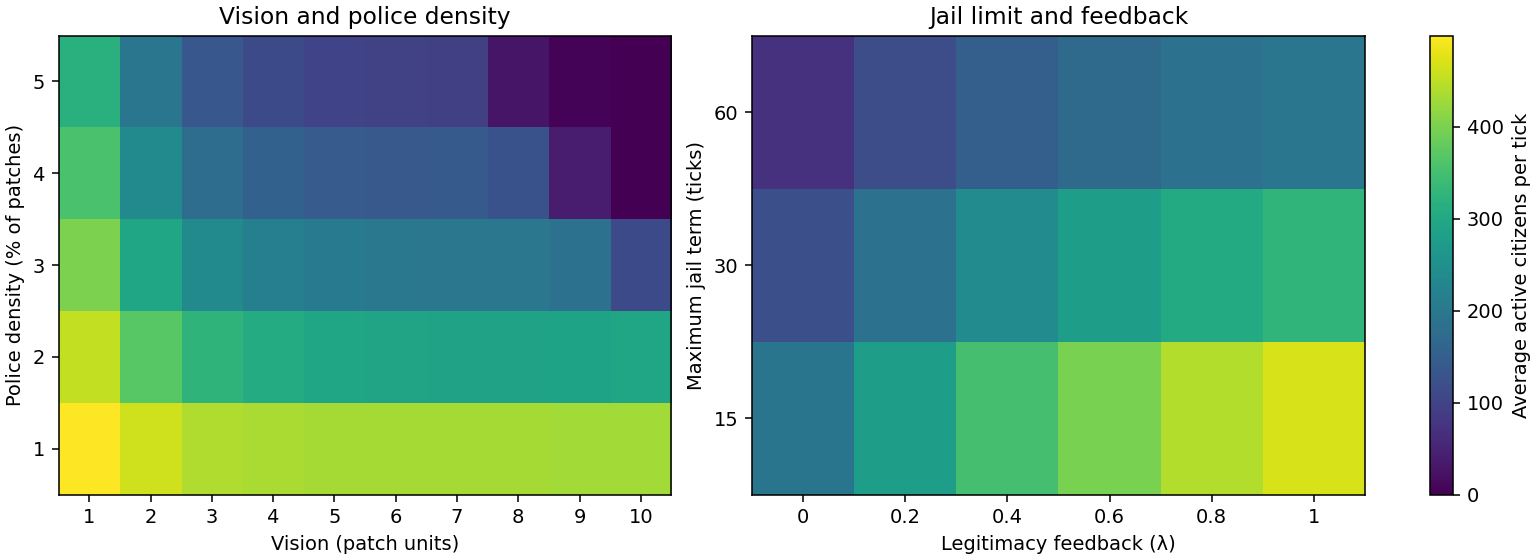

In [6]:
activity_by_vision = run_summary.pivot_table(
    index='police_pct', columns='vision', values='mean_active'
)
activity_by_jail = run_summary.pivot_table(
    index='max_jail', columns='feedback', values='mean_active'
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
top = max(activity_by_vision.max().max(), activity_by_jail.max().max())
image = draw_heatmap(axes[0], activity_by_vision, 'Vision (patch units)',
                     'Police density (% of patches)', 'Vision and police density', 0, top)
draw_heatmap(axes[1], activity_by_jail, 'Legitimacy feedback (λ)',
             'Maximum jail term (ticks)', 'Jail limit and feedback', 0, top)
fig.colorbar(image, ax=axes, label='Average active citizens per tick')
plt.show()

**What we observe.** Averaging over the other inputs, activity is lowest at **vision 10 and 5% police density** (0.1 active citizens per tick) and highest at **vision 1 and 1% police density** (499.1). On the right, the lowest average is at **60 ticks and λ = 0** (71.0) and the highest is at **15 ticks and λ = 1** (468.1). These are averages over groups of settings. Table 2 shows the lowest individual combinations.

#### Table 2 · Settings with the fewest active citizens

**What it shows.** Rank all 900 settings by their average number of active citizens. First average ticks 1–180 within each run, then average the three runs for each setting. The lowest and highest seed averages show how much the result varies across the three runs. The last column gives the average percentage of citizens in jail.

In [7]:
least_active = run_summary.groupby(settings).agg(
    mean_active=('mean_active', 'mean'),
    lowest_seed_mean=('mean_active', 'min'),
    highest_seed_mean=('mean_active', 'max'),
    mean_jailed_share=('mean_jailed_share', 'mean'),
).reset_index()

least_active['mean_jailed_pct'] = 100 * least_active.pop('mean_jailed_share')
least_active = least_active.sort_values(['mean_active', *settings])
display(least_active.head(10).round(2).reset_index(drop=True))

,vision,police_pct,max_jail,feedback,mean_active,lowest_seed_mean,highest_seed_mean,mean_jailed_pct
0,9.0,5.0,60.0,0.0,0.05,0.03,0.06,1.63
1,9.0,5.0,60.0,0.4,0.05,0.04,0.07,2.02
2,10.0,5.0,60.0,0.4,0.05,0.04,0.06,2.02
3,10.0,5.0,60.0,0.8,0.05,0.03,0.08,2.31
4,10.0,4.0,60.0,0.0,0.05,0.03,0.06,1.63
5,10.0,5.0,60.0,0.0,0.06,0.02,0.09,1.63
6,10.0,5.0,60.0,0.2,0.06,0.03,0.07,1.90
7,9.0,5.0,60.0,0.2,0.06,0.05,0.07,1.90
8,10.0,5.0,60.0,0.6,0.06,0.04,0.08,2.16
9,10.0,4.0,60.0,0.2,0.06,0.03,0.10,1.90


**What we observe.** The ten lowest-activity settings shown have vision 9 or 10, police density of 4% or 5%, and a 60-tick jail limit. Their averages are so close that the first five all round to 0.05 active citizens per tick. That means activity is nearly absent on a typical tick. The first row comes first at full precision, and the ranges across the three seeds overlap. For the nearly tied settings, look at detention too. The first five average 1.63% to 2.31% of citizens in jail. Similar activity levels can come with different levels of detention.

## 2. Under what conditions do sudden outbursts occur?

**Purpose.** Use the whole sweep to see where outbursts recur. A run counts as recurrent if at least two outbursts start by tick 180. Each table reports the percentage of runs with recurring outbursts.

#### Table 3 · Recurring outbursts by vision and police density

**What it shows.** Rows give vision and columns give police density as a percentage of patches. Each cell averages **54 runs** across all jail limits, feedback levels, and seeds.

In [8]:
# A recurrent run contributes 100. Every other run contributes 0.
recurrence = run_summary.assign(recurrent_pct=100 * run_summary['pattern'].eq('recurrent'))

vision_density = recurrence.groupby(['vision', 'police_pct'])['recurrent_pct'].mean().unstack()
display(vision_density.round(1))

police_pct,1.0,2.0,3.0,4.0,5.0
vision,,,,,
1.0,0.0,0.0,0.0,0.0,0.0
2.0,0.0,0.0,0.0,5.6,9.3
3.0,0.0,5.6,18.5,37.0,38.9
4.0,0.0,11.1,37.0,48.1,59.3
5.0,5.6,27.8,38.9,64.8,74.1
6.0,3.7,35.2,42.6,72.2,77.8
7.0,5.6,38.9,50.0,72.2,77.8
8.0,5.6,38.9,51.9,68.5,7.4
9.0,5.6,38.9,51.9,9.3,0.0


**What we observe.** Recurring outbursts were most common at **vision 6–7 with 4–5% police density**. They occurred in **72–78%** of runs in those four cells. At vision 1, they never recurred at any police density. At 5% police density, recurrence fell from about **78% at vision 7** to **7% at vision 8** and **0% at vision 9–10**. Increasing vision can make repeated bursts more common up to a point.

#### Table 4 · Recurring outbursts by jail limit and legitimacy feedback

**What it shows.** Rows give maximum jail terms and columns give feedback values (λ). Each cell averages **150 runs** across all vision settings, police densities, and seeds.

In [9]:
jail_feedback = recurrence.groupby(['max_jail', 'feedback'])['recurrent_pct'].mean().unstack()
display(jail_feedback.round(1))

feedback,0.0,0.2,0.4,0.6,0.8,1.0
max_jail,,,,,,
15.0,25.3,6.0,0.7,0.0,0.0,0.0
30.0,46.0,29.3,20.0,16.7,16.0,18.0
60.0,54.7,48.0,47.3,44.7,47.3,46.7


**What we observe.** Recurring outbursts were more common with the **60-tick jail limit** than with the 15- or 30-tick limit at every feedback value tested. At λ = 0, recurrence rose from **25%** with a 15-tick limit to **55%** with a 60-tick limit. With a 15-tick limit, none of the runs with λ of 0.6 or higher had recurring outbursts. Those runs can still have sustained activity.

These averages describe where outbursts recur in the simulation. The tick-by-tick CSV records population totals, so it cannot identify the local event that triggered a particular burst.

#### Figure 2 · Where do outbursts recur?

**What it shows.** Each color represents the percentage of runs with at least two outbursts. Both panels use the same 0–100% scale and show the same averages as Tables 3 and 4.

**Read one cell.** In the left panel, find vision **7** and police density **5%**. The color represents about **78%**. That means **42 of the 54 runs** at those two settings had at least two outbursts by tick 180. Figure 1 uses color for the number of active citizens. This figure uses color for a percentage of runs.

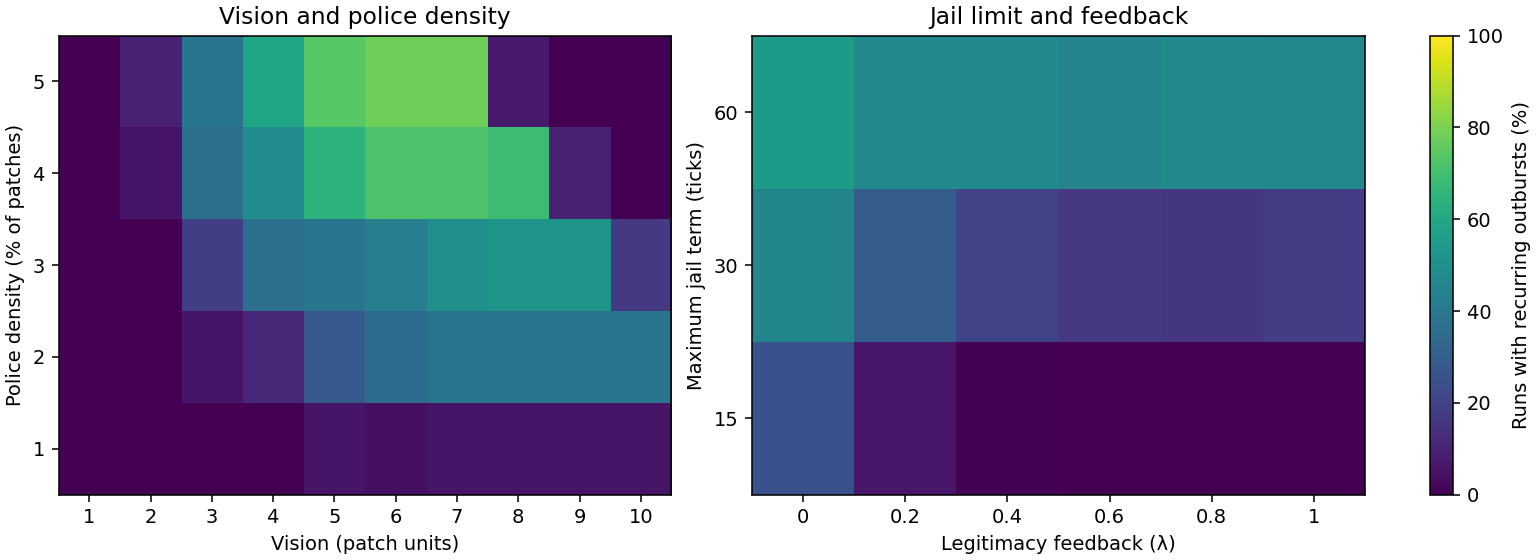

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
image = draw_heatmap(axes[0], vision_density.T, 'Vision (patch units)',
                     'Police density (% of patches)', 'Vision and police density', 0, 100)
draw_heatmap(axes[1], jail_feedback, 'Legitimacy feedback (λ)',
             'Maximum jail term (ticks)', 'Jail limit and feedback', 0, 100)
fig.colorbar(image, ax=axes, label='Runs with recurring outbursts (%)')
plt.show()

**What we observe.** Recurrence clusters around **vision 6–7 and 4–5% police density**. It is also more common with a **60-tick jail limit** than with either shorter jail limit at every feedback level. Compare this figure with Figure 1. A setting can have few recurring bursts because activity stays high in one long outburst.

## 3. How do jail policy and legitimacy interact?

**Purpose.** Test whether changing the maximum jail term has different effects when detention can lower legitimacy.

We fit a linear regression for each outcome using **all 2,700 runs**. Each run contributes one row summarizing ticks 1–180. The main terms are **maximum jail term**, **feedback λ**, and **their interaction**. The interaction lets the difference between jail limits vary at each feedback level. The model also accounts for each vision and police-density combination and for the three seeds. Jail limits and λ are treated as categories, so the model can capture a different change between each pair of levels.

The results describe the tested settings and seeds in this simulation.

In [11]:
import statsmodels.formula.api as smf

regression_data = run_summary.assign(jailed_pct=100 * run_summary['mean_jailed_share'])
outcomes = ['mean_active', 'jailed_pct', 'mean_legitimacy', 'total_arrests']
predictors = 'C(max_jail) * C(feedback) + C(vision) * C(police_pct) + C(seed)'

# Fit one model per outcome, using one row per run.
models = {
    outcome: smf.ols(f'{outcome} ~ {predictors}', data=regression_data).fit()
    for outcome in outcomes
}

# Average each fitted outcome over the same vision, density, and seed settings.
fitted = regression_data[['max_jail', 'feedback']].copy()
for outcome, model in models.items():
    fitted[outcome] = model.predict(regression_data)

adjusted = fitted.groupby(['feedback', 'max_jail'])[outcomes].mean()

#### Figure 3 · How jail policy and feedback change the fitted outcomes

**What it shows.** Each panel uses the fitted averages from the regression. Read across a row to vary feedback at a fixed jail limit and down a column to vary the jail limit at a fixed feedback level. The panels use separate color scales because their units differ.

**Read one column.** Find **λ = 1** on the right edge of each panel. Compare the bottom row (**15 ticks**) with the top row (**60 ticks**). Fitted activity falls from about **468 to 197** citizens per tick, while the fitted share jailed rises from **26.8% to 55.8%**. Use each panel’s own color bar to read its values.

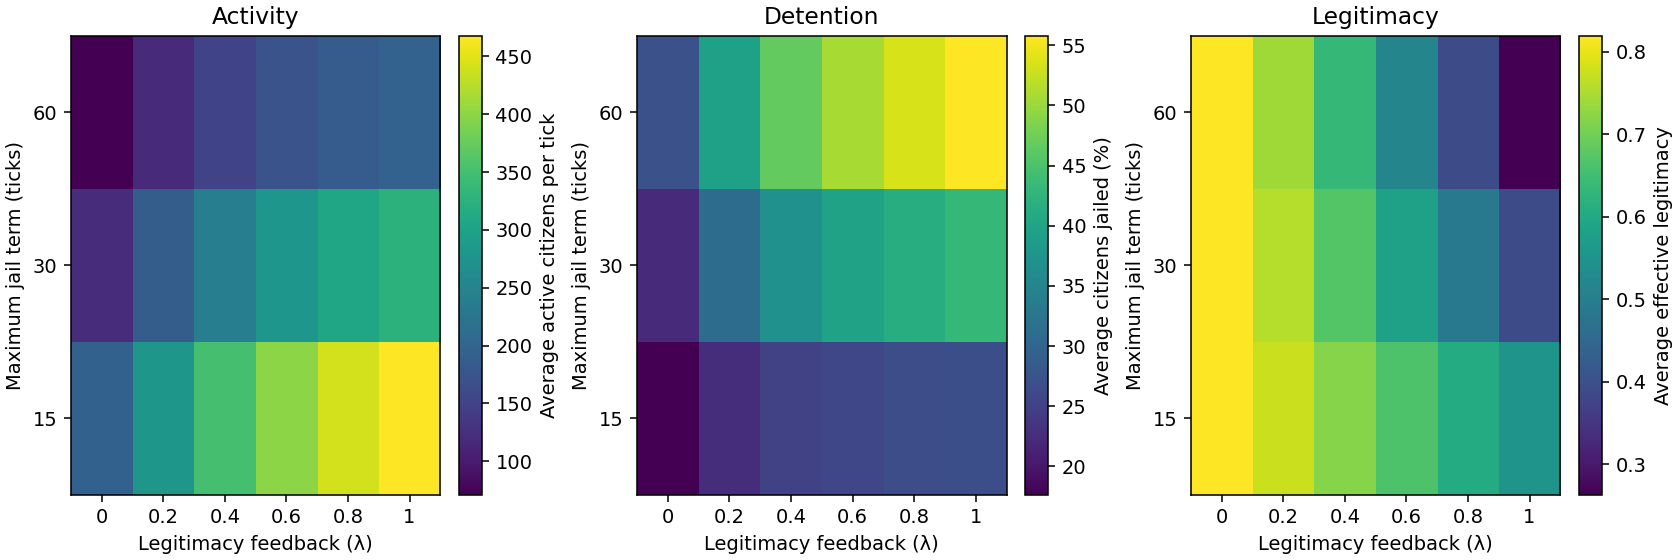

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
for ax, outcome, title, units in zip(
    axes,
    ['mean_active', 'jailed_pct', 'mean_legitimacy'],
    ['Activity', 'Detention', 'Legitimacy'],
    ['Average active citizens per tick', 'Average citizens jailed (%)', 'Average effective legitimacy'],
):
    grid = adjusted[outcome].unstack('feedback')
    image = draw_heatmap(ax, grid, 'Legitimacy feedback (λ)',
                         'Maximum jail term (ticks)', title)
    fig.colorbar(image, ax=ax, label=units)
plt.show()

**What we observe.** Higher feedback goes with more activity, more detention, and lower effective legitimacy at each jail limit. Moving from a 15- to a 60-tick limit at the same feedback value lowers activity and raises the jailed share. The legitimacy panel stays at 0.82 down the λ = 0 column. With positive feedback, longer limits lower effective legitimacy. Table 6 measures how much the jail-term effect differs across feedback values.

#### Table 5 · Fitted outcomes for each jail limit and feedback level

**What it shows.** Within each λ, compare the fitted outcomes for 15, 30, and 60 ticks. Each row averages over the same 150 combinations of vision, police density, and seed. **Arrests per run** measures how often detention starts. **Citizens jailed (%)** measures how many are detained on a typical tick.

In [13]:
display(adjusted.rename(columns={
    'mean_active': 'Active citizens per tick',
    'jailed_pct': 'Citizens jailed (%)',
    'mean_legitimacy': 'Effective legitimacy',
    'total_arrests': 'Arrests per run',
}).round(3))

Active citizens per tick  Citizens jailed (%)  Effective legitimacy  Arrests per run
feedback max_jail                                                                                      
0.0      15.0                       193.725               17.635                 0.820         4561.207
         30.0                       121.908               22.369                 0.820         3068.967
         60.0                        71.048               27.125                 0.820         2000.307
0.2      15.0                       280.498               22.605                 0.775         5848.667
         30.0                       188.063               31.196                 0.758         4285.027
         60.0                       118.474               39.406                 0.741         2914.440
0.4      15.0                       351.461               25.148                 0.719         6513.553
         30.0                       241.414               36.983                 0.672         5078.747
         60.0                       151.402               46.647                 0.633         3439.107
0.6      15.0                       398.556               25.806                 0.665         6677.033
         30.0                       279.065               39.674                 0.582         5456.907
         60.0                       172.809               50.741                 0.516         3745.840
0.8      15.0                       441.701               26.686                 0.607         6907.953
         30.0                       305.747               41.487                 0.488         5712.133
         60.0                       186.091               53.422                 0.393         3936.587
1.0      15.0                       468.141               26.836                 0.552         6947.300
         30.0                       325.864               42.984                 0.390         5917.460
         60.0                       196.665               55.806                 0.263         4125.820

**What we observe.** At every feedback level, the fitted 60-tick limit yields fewer active citizens and a larger share in jail than the 15-tick limit. With the jail limit held at 60 ticks, raising λ from 0 to 1 increases average activity from about **71 to 197** citizens. The fitted jailed share rises from **27.1% to 55.8%**, and effective legitimacy falls from **0.82 to 0.26**. These are the simulated outcomes under the assumed feedback rule.

#### Table 6 · How the effect of a longer jail term changes with feedback

**What it shows.** Each row subtracts the result at a **15-tick** jail limit from the result at a **60-tick** limit at the same λ. Read down a column to see how the effect of the longer jail limit changes as detention has a stronger effect on legitimacy.

In [14]:
# At each λ, subtract the fitted value at 15 ticks from the value at 60 ticks.
jail_effect = adjusted.xs(60, level='max_jail') - adjusted.xs(15, level='max_jail')
display(jail_effect.rename(columns={
    'mean_active': 'Change in active citizens',
    'jailed_pct': 'Change in jailed share (percentage points)',
    'mean_legitimacy': 'Change in effective legitimacy',
    'total_arrests': 'Change in arrests per run',
}).round(3))

,Change in active citizens,Change in jailed share (percentage points),Change in effective legitimacy,Change in arrests per run
feedback,,,,
0.0,-122.677,9.490,-0.000,-2560.900
0.2,-162.024,16.801,-0.034,-2934.227
0.4,-200.059,21.498,-0.086,-3074.447
0.6,-225.747,24.936,-0.150,-2931.193
0.8,-255.610,26.735,-0.214,-2971.367
1.0,-271.476,28.969,-0.288,-2821.480


**What we observe.** Going from 15 to 60 ticks reduces the average number of active citizens by about **123** at λ = 0 and **271** at λ = 1. The jailed share increases by **9.5** and **29.0 percentage points**, respectively, even as arrests per run fall in both cases. The key comparison is how much the jail-term effect changes across feedback levels. Compared with λ = 0, the reduction in activity is about **149 citizens larger** at λ = 1, and the increase in the jailed share is **19.5 percentage points larger**.